| العمود                | المعنى بالعربي                                  | مثال توضيحي                |
| --------------------- | ----------------------------------------------- | -------------------------- |
| `listing_id`          | رقم مميز لكل إعلان سيارة                        | 1001                       |
| `brand`               | ماركة السيارة                                   | Toyota                     |
| `model`               | موديل السيارة                                   | Corolla                    |
| `year`                | سنة تصنيع السيارة                               | 2020                       |
| `mileage_km`          | إجمالي المسافة التي قطعتها السيارة بالكيلومتر   | 85000                      |
| `transmission`        | نوع ناقل الحركة                                 | Automatic / Manual         |
| `fuel_type`           | نوع الوقود المستخدم                             | Petrol / Diesel / Electric |
| `engine_cc`           | سعة المحرك بالسنتيمتر المكعب                    | 1600                       |
| `body_type`           | نوع هيكل السيارة                                | Sedan / SUV / Hatchback    |
| `color`               | لون السيارة                                     | White / Black              |
| `city`                | المدينة التي تُعرض فيها السيارة للبيع           | Cairo / Alexandria         |
| `seller_type`         | نوع البائع                                      | Dealer / Individual        |
| `accident_history`    | هل تعرضت السيارة لحوادث سابقة؟                  | Yes / No                   |
| `previous_owners`     | عدد المالكين السابقين للسيارة                   | 2                          |
| `condition_rating`    | تقييم الحالة العامة للسيارة                     | 1–5 مثلًا                  |
| `photos_count`        | عدد الصور الموجودة في الإعلان                   | 8                          |
| `price_egp`           | سعر السيارة بالجنيه المصري                      | 750000                     |
| `sold_within_30_days` | هل تم بيع السيارة خلال 30 يومًا من نشر الإعلان؟ | 1 = نعم، 0 = لا            |

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
from tqdm import tqdm
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


In [6]:
!pip install catboost


In [7]:
df = pd.read_csv(r'/content/used_cars_dataset.csv')

In [8]:
df.head()

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           3000 non-null   object 
 1   brand                3000 non-null   object 
 2   model                3000 non-null   object 
 3   year                 3000 non-null   int64  
 4   mileage_km           2822 non-null   float64
 5   transmission         2941 non-null   object 
 6   fuel_type            2940 non-null   object 
 7   engine_cc            2879 non-null   float64
 8   body_type            3000 non-null   object 
 9   color                2851 non-null   object 
 10  city                 2941 non-null   object 
 11  seller_type          2942 non-null   object 
 12  accident_history     3000 non-null   object 
 13  previous_owners      2881 non-null   float64
 14  condition_rating     2851 non-null   object 
 15  photos_count         2907 non-null   f

In [10]:
df.describe()

,year,mileage_km,engine_cc,previous_owners,photos_count,price_egp
count,3000.000000,2.822000e+03,2879.000000,2881.000000,2907.000000,3.000000e+03
mean,2018.174333,1.093424e+05,1654.430358,1.887886,10.543172,7.555841e+05
std,37.275449,2.707599e+05,526.287599,1.008779,8.393483,2.043534e+06
min,0.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000e+00
25%,2017.000000,5.020000e+04,1500.000000,1.000000,8.000000,3.300000e+05
50%,2020.000000,8.570000e+04,1600.000000,2.000000,10.000000,5.525000e+05
75%,2022.000000,1.339250e+05,1600.000000,2.000000,13.000000,9.400000e+05
max,2050.000000,9.999999e+06,20000.000000,6.000000,300.000000,1.000000e+08


In [11]:
df.describe(include=object)

,listing_id,brand,model,transmission,fuel_type,body_type,color,city,seller_type,accident_history,condition_rating,sold_within_30_days
count,3000,3000,3000,2941,2940,3000,2851,2941,2942,3000,2851,3000
unique,2940,53,14,4,3,2,7,27,4,4,4,2
top,CAR-50004,Hyundai,Corolla,Automatic,Petrol,Sedan,White,Cairo,Individual,No,Good,No
freq,2,489,405,1927,2004,2522,792,841,1958,2396,1435,1635


In [12]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


listing_id:
['CAR-52762' 'CAR-52678' 'CAR-52822' ... 'CAR-50347' 'CAR-50986'
 'CAR-50666']

brand:
['MG' 'Kia' 'Skoda' 'Fiat' 'Mitsubishi' 'Toyota' 'Hyundai' 'Nissan'
 'Chevrolet' 'Mercedes' 'TOYOTA' 'BMW' 'Renault' 'KIA' 'Mercedes-Benz'
 'CHERY' 'Chery' 'chevrolet' 'nissan' 'hyundai' 'Toyota ' 'NISSAN' 'kia'
 'hyundai ' 'Chery ' 'chery' 'mitsubishi' 'fiat' 'toyota' 'mg'
 'mercedes-benz' 'SKODA' 'Nissan ' 'BMW ' 'HYUNDAI' 'CHEVROLET' 'bmw'
 'skoda' 'MITSUBISHI' 'Hyundai ' 'renault' 'RENAULT' 'MERCEDES-BENZ'
 'Renault ' 'Chevrolet ' 'Skoda ' 'Kia ' 'MG ' 'NISSAN ' 'Fiat ' 'FIAT'
 'Mitsubishi ' 'bmw ']

model:
['ZS' 'Cerato' 'Octavia' 'Tipo' 'Lancer' 'Corolla' 'Elantra' 'Sunny'
 'Tucson' 'Optra' 'C200' '320i' 'Logan' 'Tiggo 7']

year:
[2021 2023 2009 2019 2022 2010 2017 2020 2025 2024 2018 2005 2013 2015
 2016 2012 2011 2008 2014 2006 2031 2007    0 1899 2026 2050 1985 1900
 2035 1970]

mileage_km:
[  64900.      nan  224500. ...   10800. 1100000.  177400.]

transmission:
['Automatic' '

In [13]:
text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    df[col] = df[col].str.strip().str.title()

In [14]:
df['transmission'] = df['transmission'].replace({
    'Auto': 'Automatic',
    'Mt': 'Manual'
})

In [15]:
df['accident_history'] = df['accident_history'].replace({
    'N': 'No',
    'Y': 'Yes'
})

In [16]:
df[df['engine_cc']==df['engine_cc'].min()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
787,Car-51241,Nissan,Sunny,2007,261700.0,Manual,Petrol,0.0,Sedan,Silver,Alexandria,Individual,No,2.0,Good,12.0,129000,No
1799,Car-50572,Chevrolet,Optra,2018,131700.0,Automatic,Hybrid,0.0,Sedan,White,Banha,Dealer,No,1.0,Fair,12.0,234000,No


In [17]:
df['engine_cc']=df['engine_cc'].replace({20000:2000,
                                         16000:1600,
                                         12000:1200,
                                         9000:1900,
                                         0:1500,
                                         5:1600,
                                         100:1400})

In [18]:
df['photos_count'] = df['photos_count'].replace({
    300: 30,
    250: 25,
    150: 15,
    99: 9,

})

In [19]:
df.drop(df[df['mileage_km'] == 0].index, inplace=True)

In [20]:
df.drop(df[df['year'] == 0].index, inplace=True)

In [21]:
df.drop(df[df['price_egp'] == 0].index, inplace=True)

In [22]:
df[df['mileage_km']==df['mileage_km'].max()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
1816,Car-50796,Kia,Cerato,2020,9999999.0,Automatic,Petrol,1600.0,Sedan,White,NaN,Individual,No,2.0,Good,9.0,643000,Yes


In [23]:
df['mileage_km'] = df['mileage_km'].replace({9999999:99999,
                                            8888888:88888,
                                            3000000:300000,
                                             2500000:250000,
                                             1500000:150000,
                                             1200000:120000,
                                             1100000:110000,
                                             999999:99999,
                                             950000:95000})

In [24]:
df['previous_owners'] = df['previous_owners'].round().astype('Int64')
df['photos_count'] = df['photos_count'].round().astype('Int64')

In [25]:
df.duplicated().sum()

np.int64(40)

In [26]:
df.drop_duplicates(inplace=True)

In [27]:
df[df['listing_id'].duplicated(keep=False)].sort_values(
    by='listing_id',
    ascending=True
)

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
2159,Car-50129,Mitsubishi,Lancer,2021,87100.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Individual,No,2,Excellent,7,329000,Yes
446,Car-50129,Mitsubishi,Lancer,2021,87100.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Individual,No,2,Excellent,7,339000,Yes
2048,Car-50342,Mercedes-Benz,C200,2017,130400.0,Automatic,Petrol,1600.0,Sedan,Black,Port Said,Individual,No,1,Good,10,1213000,No
2868,Car-50342,Mercedes-Benz,C200,2017,130400.0,Automatic,Petrol,1600.0,Sedan,Black,Port Said,Individual,No,1,Good,10,1177000,No
1169,Car-50457,Mg,Zs,2024,24800.0,Automatic,Hybrid,1500.0,Suv,Black,Alexandria,Dealer,No,2,Fair,12,1080000,Yes
2383,Car-50457,Mg,Zs,2024,24800.0,Automatic,Hybrid,1500.0,Suv,Black,Alexandria,Dealer,No,2,Fair,12,1113000,Yes
2873,Car-50518,Mercedes-Benz,C200,2020,85300.0,Automatic,Petrol,1600.0,Sedan,Blue,Giza,Dealer,No,1,Excellent,14,1637000,No
2777,Car-50518,Mercedes-Benz,C200,2020,85300.0,Automatic,Petrol,1600.0,Sedan,Blue,Giza,Dealer,No,1,Excellent,14,1688000,No
2432,Car-50519,Hyundai,Elantra,2019,90900.0,Automatic,Diesel,1600.0,Sedan,Grey,Cairo,Individual,No,5,Good,8,540000,No
1863,Car-50519,Hyundai,Elantra,2019,90900.0,Automatic,Diesel,1600.0,Sedan,Grey,Cairo,Individual,No,5,Good,8,557000,No


In [28]:
df.drop_duplicates(subset='listing_id', keep='first', inplace=True)

In [29]:
df.isnull().sum()

,0
listing_id,0
brand,0
model,0
year,0
mileage_km,175
transmission,58
fuel_type,58
engine_cc,117
body_type,0
color,146


In [30]:
df[df['mileage_km'].isnull()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
1,Car-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1,Good,12,1012000,No
9,Car-51630,Mg,Zs,2017,NaN,Automatic,Petrol,1500.0,Suv,White,Mansoura,Individual,No,3,Good,8,416000,No
23,Car-52348,Hyundai,Elantra,2005,NaN,Automatic,Petrol,2000.0,Sedan,Blue,Alexandria,Individual,No,3,Fair,3,157000,No
63,Car-51627,Toyota,Corolla,2023,NaN,Automatic,Hybrid,1800.0,Sedan,Black,Alexandria,Individual,No,1,Good,13,1333000,Yes
79,Car-51252,Nissan,Sunny,2012,NaN,Manual,Petrol,1500.0,Sedan,Black,Cairo,Dealer,Yes,1,Good,10,146000,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2947,Car-50676,Hyundai,Elantra,2018,NaN,Automatic,Petrol,2000.0,Sedan,Red,Alexandria,Dealer,No,3,Fair,14,530000,No
2957,Car-52067,Nissan,Sunny,2022,NaN,Manual,Petrol,1500.0,Sedan,White,Mansoura,Dealer,No,<NA>,Poor,<NA>,483000,No
2960,Car-50132,Hyundai,Elantra,2014,NaN,Automatic,Petrol,2000.0,Sedan,Silver,Tanta,Individual,No,1,Excellent,10,382000,No
2970,Car-50847,Kia,Cerato,2023,NaN,Automatic,Hybrid,1600.0,Sedan,White,Alexandria,Individual,No,1,Good,7,1063000,No


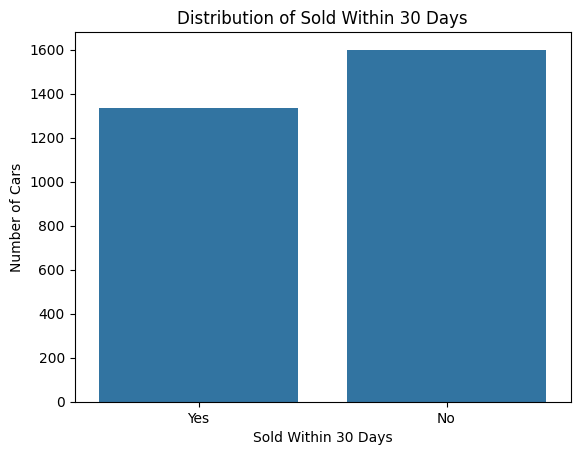

In [31]:
sns.countplot(data=df, x='sold_within_30_days')

plt.title('Distribution of Sold Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Number of Cars')
plt.show()

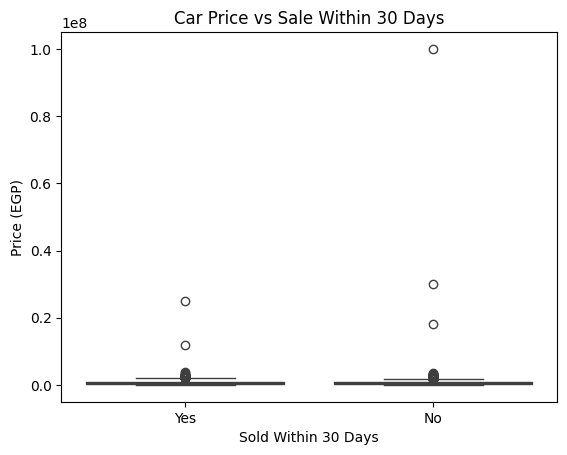

In [32]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='price_egp'
)

plt.title('Car Price vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Price (EGP)')
plt.show()

In [33]:
df.nlargest(20, 'price_egp')[
    ['brand', 'model', 'year', 'price_egp']
]

,brand,model,year,price_egp
178,Nissan,Sunny,2008,99999999
2552,Chery,Tiggo 7,2019,30000000
1182,Skoda,Octavia,2013,25000000
358,Skoda,Octavia,2015,18000000
499,Hyundai,Elantra,2022,12000000
1482,Mercedes-Benz,C200,2026,3818000
1653,Mercedes-Benz,C200,2023,3585000
1867,Mercedes-Benz,C200,2025,3455000
2023,Mercedes-Benz,C200,2024,3366000
1620,Mercedes-Benz,C200,2025,3332000


In [34]:
df.drop(index=[178,2552,1182,358], inplace=True)
df.reset_index(drop=True, inplace=True)
df['price_egp'].replace(12000000,1200000, inplace=True)

/tmp/ipykernel_1493/1846346365.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['price_egp'].replace(12000000,1200000, inplace=True)


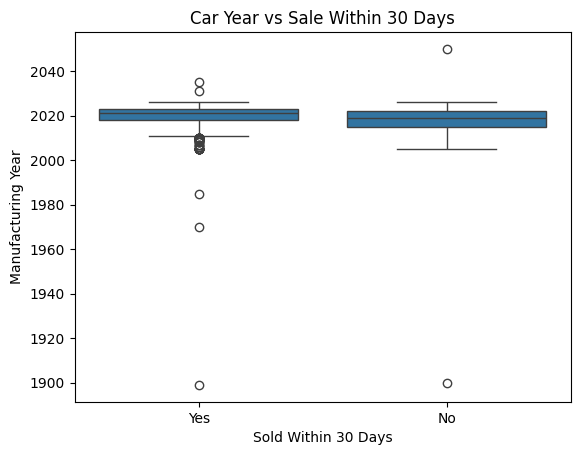

In [35]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='year'
)

plt.title('Car Year vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Manufacturing Year')
plt.show()

In [36]:
df = df[(df['year'] > 1990) & (df['year'] < 2027)]

In [37]:
df[(df['year'] < 2010) & (df['sold_within_30_days'] == 'Yes')]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
65,Car-50617,Mg,Zs,2006,274700.0,Automatic,Diesel,1500.0,Suv,White,Alexandria,Individual,No,4,NaN,10,149000,Yes
222,Car-52235,Toyota,Corolla,2005,237500.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Dealer,No,3,Good,12,230000,Yes
252,Car-50689,Hyundai,Elantra,2007,306200.0,NaN,Petrol,1600.0,Sedan,NaN,Cairo,Dealer,No,1,Good,9,211000,Yes
270,Car-50428,Hyundai,Elantra,2006,299700.0,Automatic,Petrol,2000.0,Sedan,NaN,Giza,Dealer,No,4,Fair,12,196000,Yes
295,Car-52030,Toyota,Corolla,2007,244000.0,Automatic,Petrol,1600.0,Sedan,White,Mansoura,Individual,No,1,Good,8,199000,Yes
375,Car-50389,Chery,Tiggo 7,2005,312300.0,Automatic,Petrol,1500.0,Suv,Black,Assiut,Individual,No,4,Fair,4,193000,Yes
434,Car-51765,Fiat,Tipo,2008,238000.0,Manual,Petrol,1600.0,Sedan,Grey,Giza,Individual,No,3,NaN,11,87000,Yes
500,Car-50979,Toyota,Corolla,2009,200800.0,Automatic,Petrol,1800.0,Sedan,Black,NaN,Dealer,No,1,Excellent,11,226000,Yes
676,Car-51405,Hyundai,Elantra,2009,242800.0,Automatic,Petrol,2000.0,Sedan,Black,Assiut,Individual,No,2,Good,8,137000,Yes
748,Car-52510,Chery,Tiggo 7,2005,249900.0,Automatic,Diesel,1600.0,Suv,White,Giza,Individual,No,3,Fair,11,174000,Yes


In [38]:
df.shape

(2921, 18)

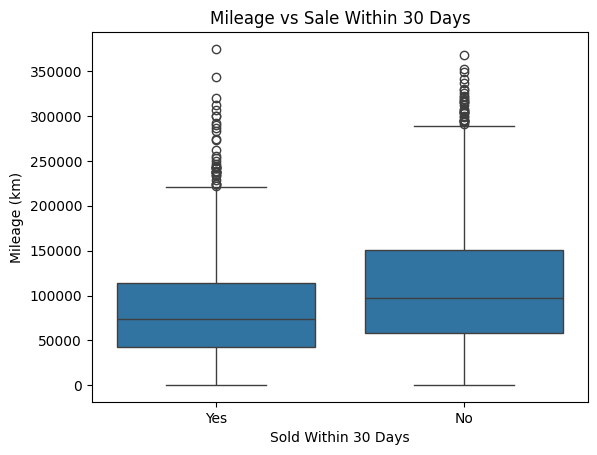

In [39]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='mileage_km'
)

plt.title('Mileage vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Mileage (km)')
plt.show()

In [40]:
df.nlargest(20, 'mileage_km')[
    ['brand', 'model', 'year', 'price_egp','mileage_km']
]

,brand,model,year,price_egp,mileage_km
1985,Hyundai,Elantra,2005,162000,374600.0
2314,Chery,Tiggo 7,2005,220000,368300.0
189,Toyota,Corolla,2005,251000,352300.0
1357,Kia,Cerato,2005,167000,349300.0
1409,Mercedes-Benz,C200,2005,363000,343100.0
1673,Bmw,320I,2005,333000,341300.0
216,Skoda,Octavia,2005,204000,336200.0
1291,Hyundai,Tucson,2005,232000,329500.0
1456,Mercedes-Benz,C200,2005,539000,329100.0
220,Mg,Zs,2005,212000,325600.0


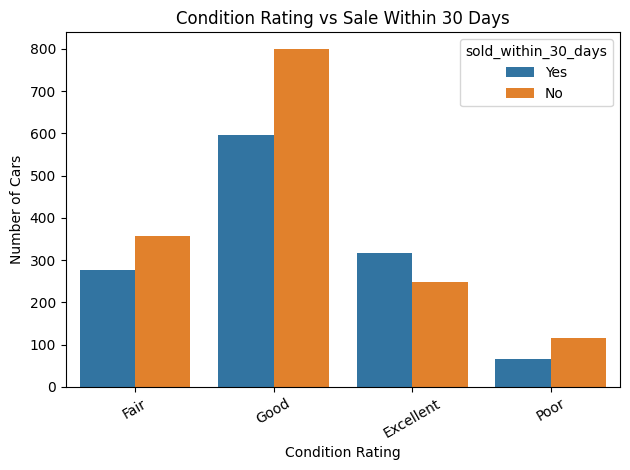

In [41]:
sns.countplot(
    data=df,
    x='condition_rating',
    hue='sold_within_30_days'
)

plt.title('Condition Rating vs Sale Within 30 Days')
plt.xlabel('Condition Rating')
plt.ylabel('Number of Cars')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

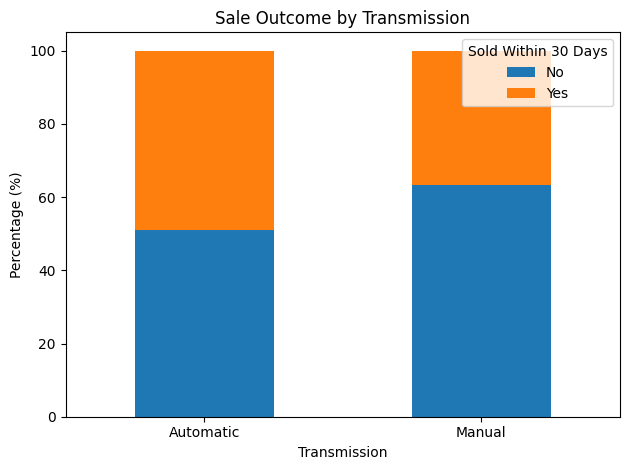

In [42]:
sale_rate = pd.crosstab(
    df['transmission'],
    df['sold_within_30_days'],
    normalize='index'
) * 100

sale_rate.plot(kind='bar', stacked=True)

plt.title('Sale Outcome by Transmission')
plt.xlabel('Transmission')
plt.ylabel('Percentage (%)')
plt.legend(title='Sold Within 30 Days')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

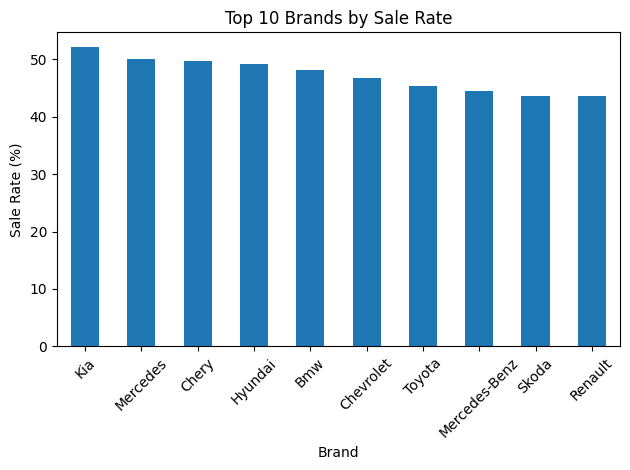

In [43]:
brand_sale_rate = (
    df.groupby('brand')['sold_within_30_days']
      .apply(lambda x: x.eq('Yes').mean() * 100)
      .sort_values(ascending=False)
      .head(10)
)

brand_sale_rate.plot(kind='bar')

plt.title('Top 10 Brands by Sale Rate')
plt.xlabel('Brand')
plt.ylabel('Sale Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

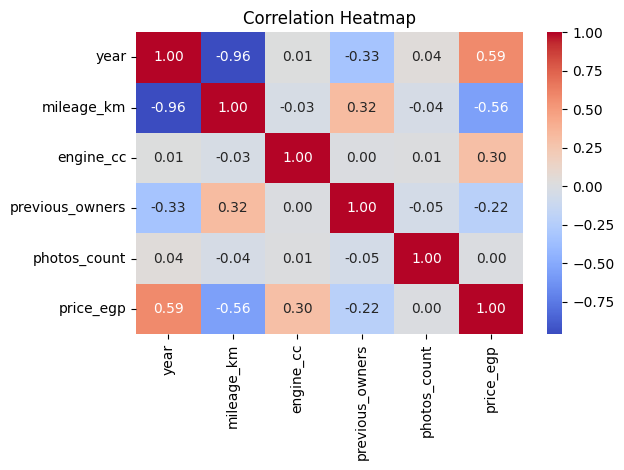

In [44]:
numeric_cols = [
    'year',
    'mileage_km',
    'engine_cc',
    'previous_owners',
    'photos_count',
    'price_egp'
]

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [45]:
X = df.drop(columns=['listing_id', 'sold_within_30_days'])
y = df['sold_within_30_days']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [46]:

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(include='object').columns

# Numeric columns: Median
num_imputer = SimpleImputer(strategy='median')

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

# Categorical columns: Most frequent
cat_imputer = SimpleImputer(strategy='most_frequent')

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

In [47]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
# Save training feature names
feature_columns = X_train.columns.tolist()
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [48]:
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

In [49]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [50]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[233  86]
 [110 156]]


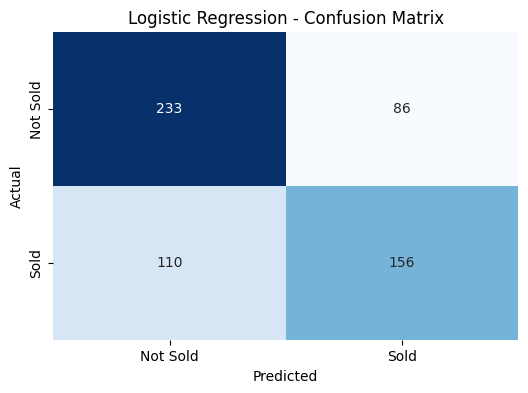


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.68      0.73      0.70       319
    Sold within 30 days       0.64      0.59      0.61       266

               accuracy                           0.66       585
              macro avg       0.66      0.66      0.66       585
           weighted avg       0.66      0.66      0.66       585

ROC-AUC: 0.7117755203054659


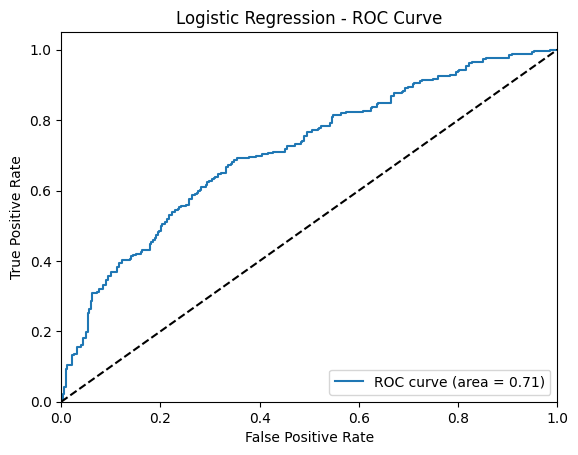

PR AUC: 0.6739679439056627


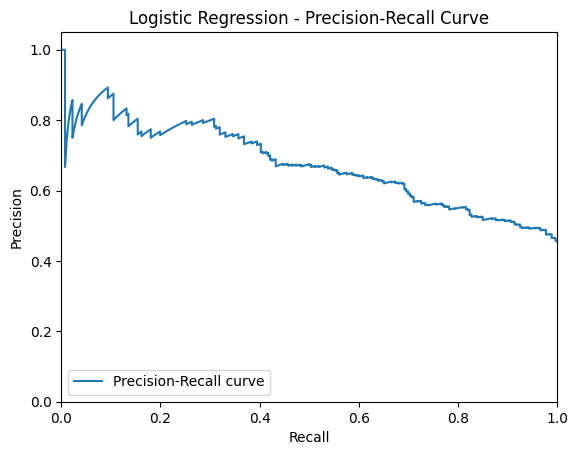

  8%|▊         | 1/13 [00:01<00:13,  1.11s/it]


Confusion Matrix:
 [[191 128]
 [149 117]]


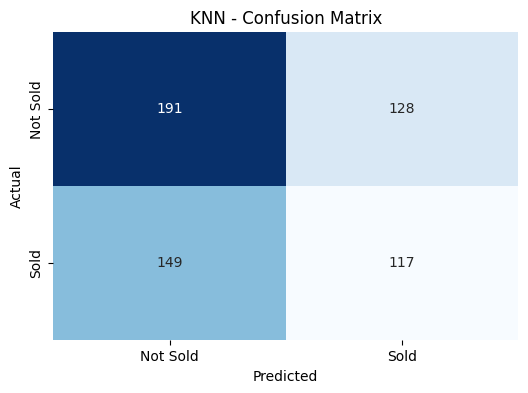


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.56      0.60      0.58       319
    Sold within 30 days       0.48      0.44      0.46       266

               accuracy                           0.53       585
              macro avg       0.52      0.52      0.52       585
           weighted avg       0.52      0.53      0.52       585

ROC-AUC: 0.5341409951210314


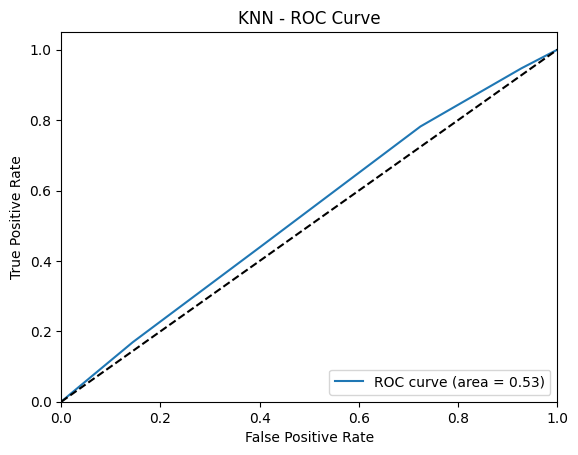

PR AUC: 0.47511073300182033


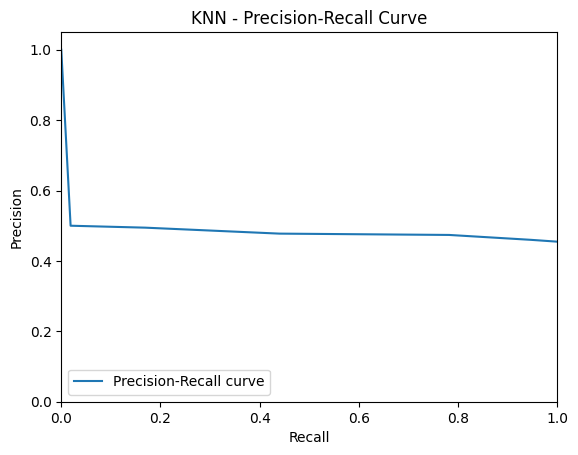

 15%|█▌        | 2/13 [00:02<00:13,  1.19s/it]


Confusion Matrix:
 [[213 106]
 [115 151]]


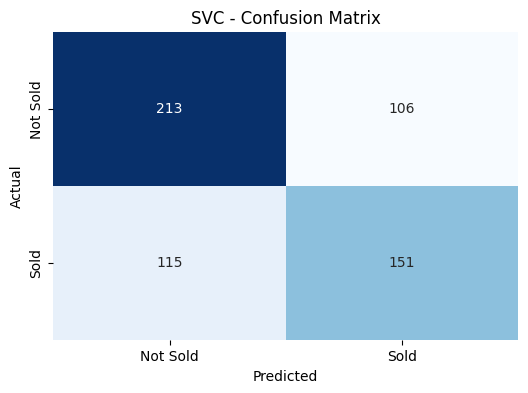


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.65      0.67      0.66       319
    Sold within 30 days       0.59      0.57      0.58       266

               accuracy                           0.62       585
              macro avg       0.62      0.62      0.62       585
           weighted avg       0.62      0.62      0.62       585

ROC-AUC: 0.6676644589530252


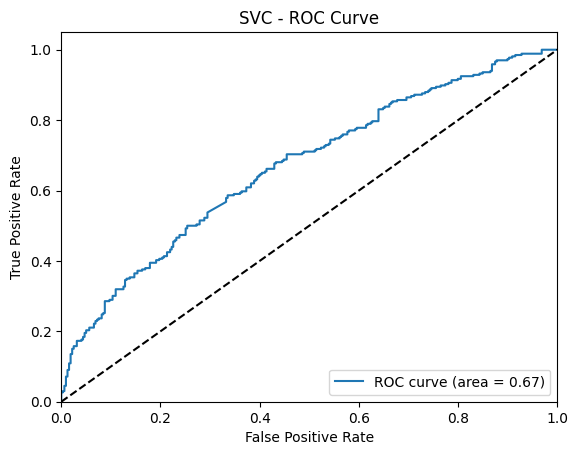

PR AUC: 0.6408126737559948


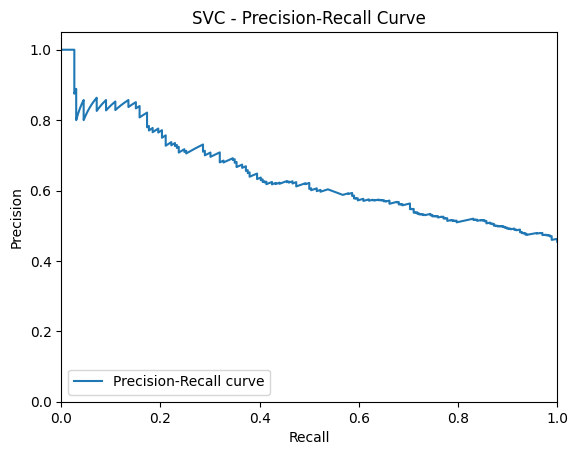

 23%|██▎       | 3/13 [00:08<00:34,  3.42s/it]


Confusion Matrix:
 [[187 132]
 [108 158]]


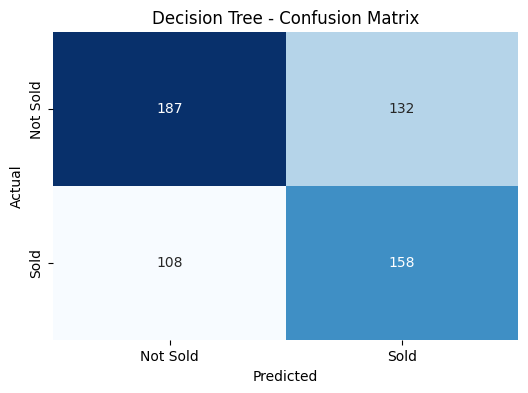


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.63      0.59      0.61       319
    Sold within 30 days       0.54      0.59      0.57       266

               accuracy                           0.59       585
              macro avg       0.59      0.59      0.59       585
           weighted avg       0.59      0.59      0.59       585

ROC-AUC: 0.5900959294788697


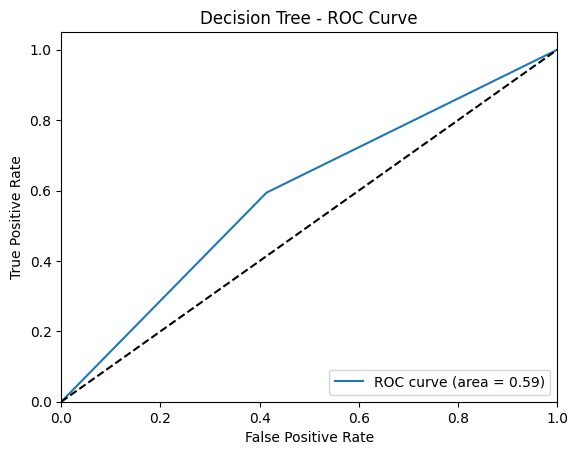

PR AUC: 0.5082347779262479


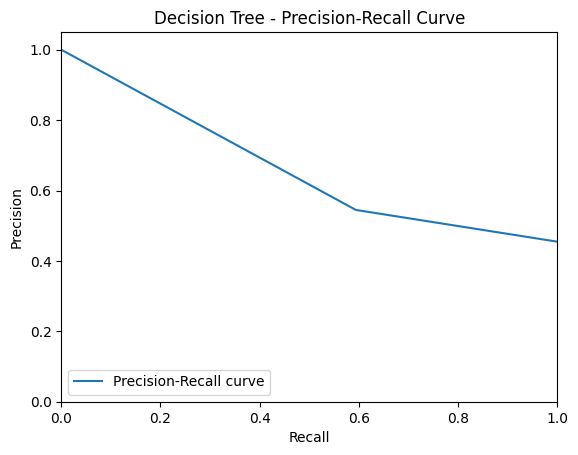

 31%|███       | 4/13 [00:10<00:24,  2.72s/it]


Confusion Matrix:
 [[155 164]
 [110 156]]


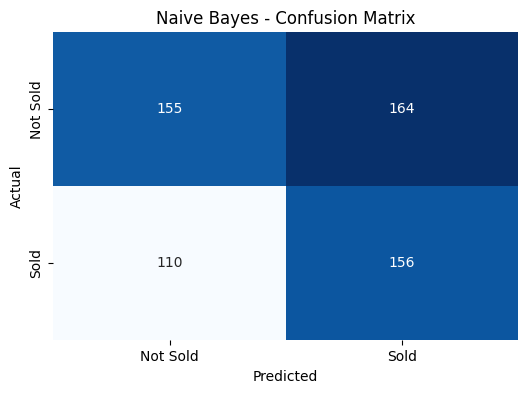


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.58      0.49      0.53       319
    Sold within 30 days       0.49      0.59      0.53       266

               accuracy                           0.53       585
              macro avg       0.54      0.54      0.53       585
           weighted avg       0.54      0.53      0.53       585

ROC-AUC: 0.5681877106559503


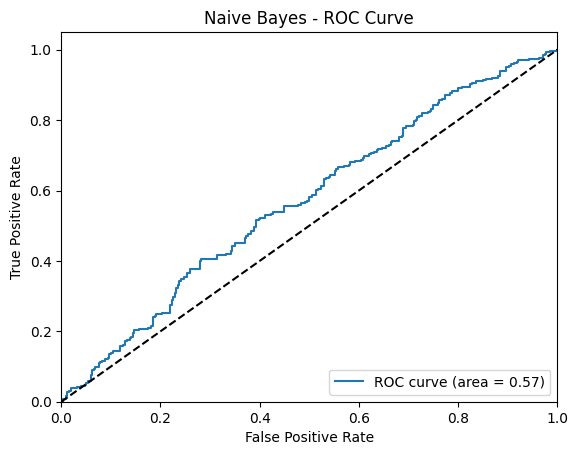

PR AUC: 0.5057357906049176


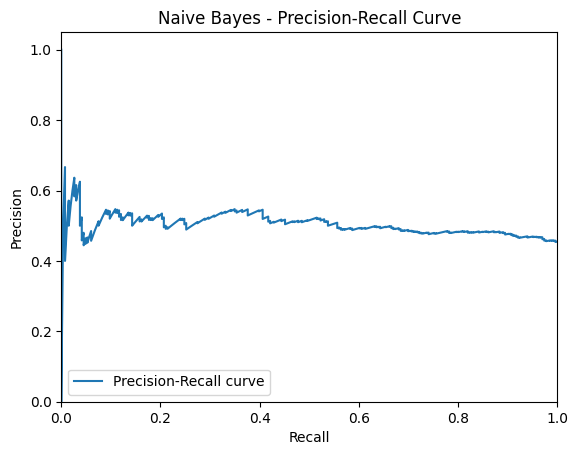

 38%|███▊      | 5/13 [00:12<00:21,  2.63s/it]


Confusion Matrix:
 [[223  96]
 [112 154]]


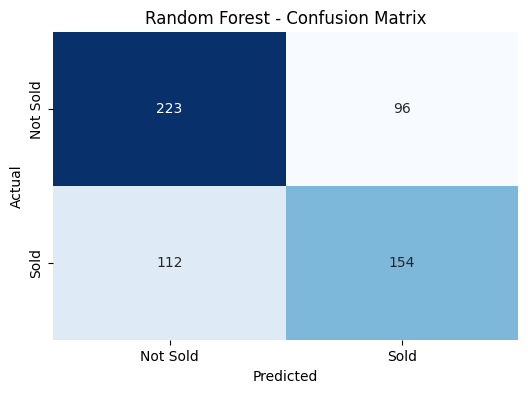


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.67      0.70      0.68       319
    Sold within 30 days       0.62      0.58      0.60       266

               accuracy                           0.64       585
              macro avg       0.64      0.64      0.64       585
           weighted avg       0.64      0.64      0.64       585

ROC-AUC: 0.6759021377896152


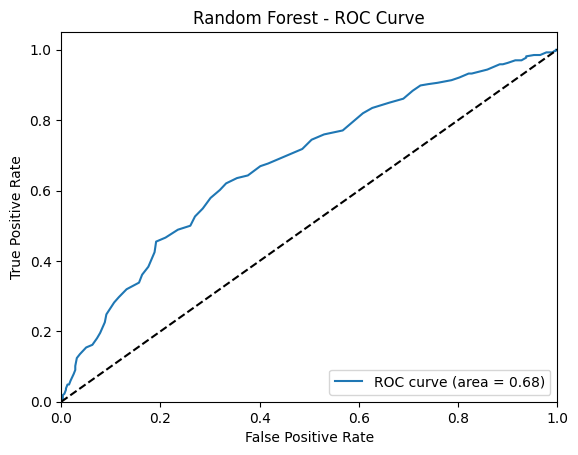

PR AUC: 0.6179175669366468


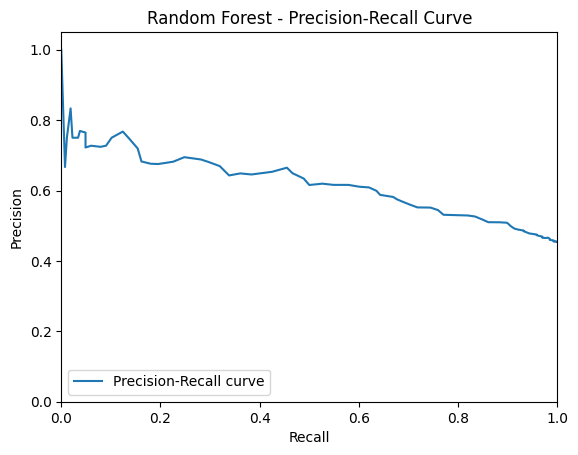

 46%|████▌     | 6/13 [00:14<00:17,  2.56s/it]


Confusion Matrix:
 [[221  98]
 [125 141]]


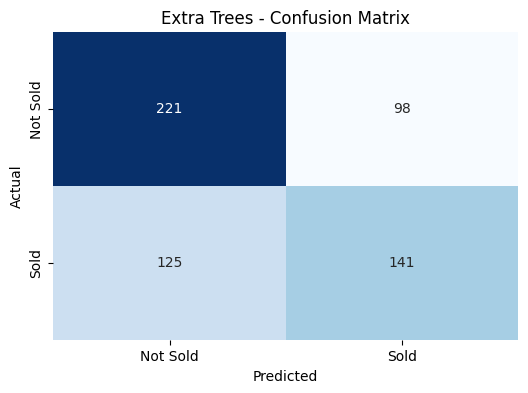


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.64      0.69      0.66       319
    Sold within 30 days       0.59      0.53      0.56       266

               accuracy                           0.62       585
              macro avg       0.61      0.61      0.61       585
           weighted avg       0.62      0.62      0.62       585

ROC-AUC: 0.6363636363636365


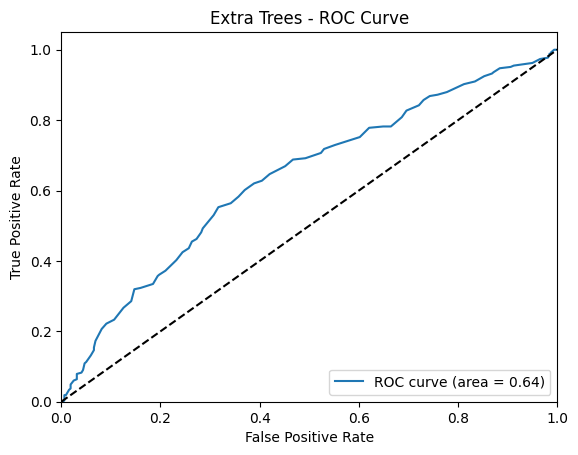

PR AUC: 0.5763540788372984


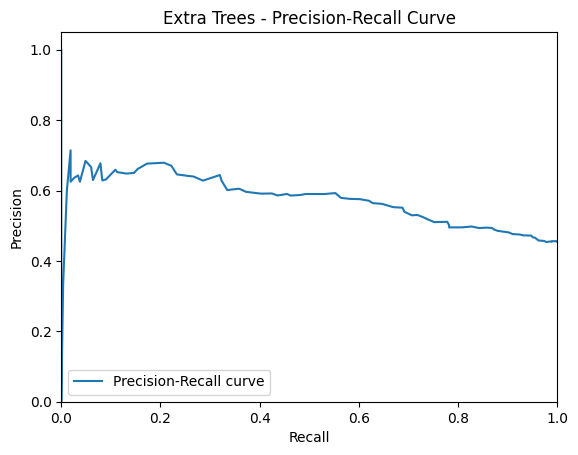

 54%|█████▍    | 7/13 [00:17<00:15,  2.55s/it]


Confusion Matrix:
 [[240  79]
 [114 152]]


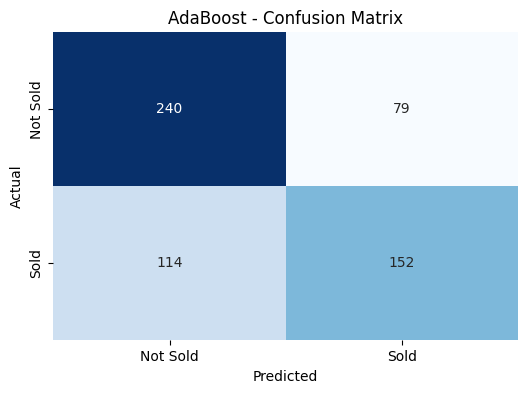


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.68      0.75      0.71       319
    Sold within 30 days       0.66      0.57      0.61       266

               accuracy                           0.67       585
              macro avg       0.67      0.66      0.66       585
           weighted avg       0.67      0.67      0.67       585

ROC-AUC: 0.7001555613170858


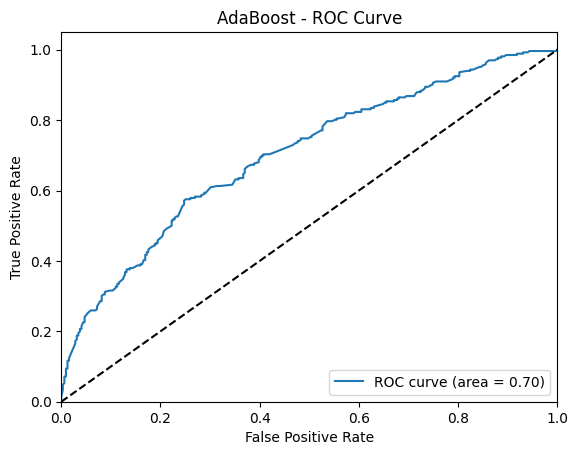

PR AUC: 0.6718311060213507


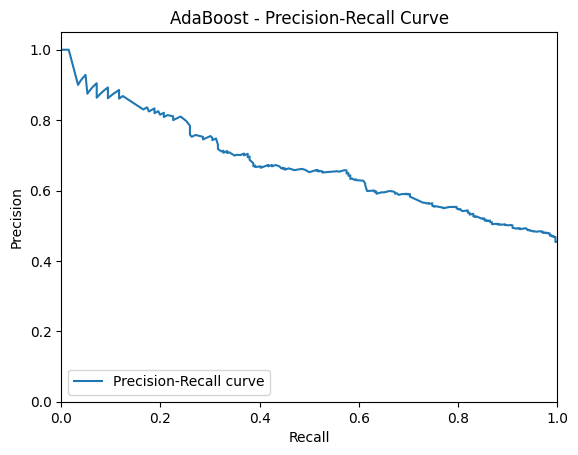

 62%|██████▏   | 8/13 [00:18<00:10,  2.17s/it]


Confusion Matrix:
 [[223  96]
 [118 148]]


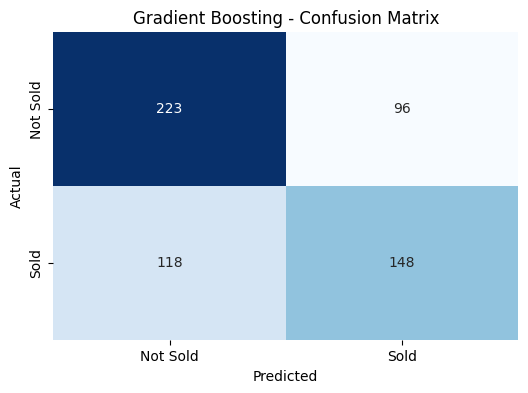


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.65      0.70      0.68       319
    Sold within 30 days       0.61      0.56      0.58       266

               accuracy                           0.63       585
              macro avg       0.63      0.63      0.63       585
           weighted avg       0.63      0.63      0.63       585

ROC-AUC: 0.6796733212341197


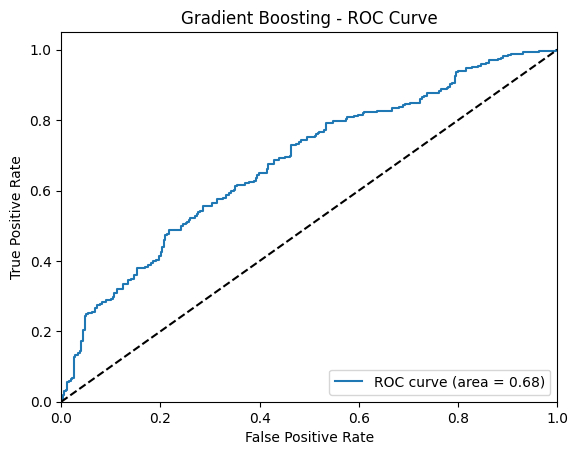

PR AUC: 0.6361988802082472


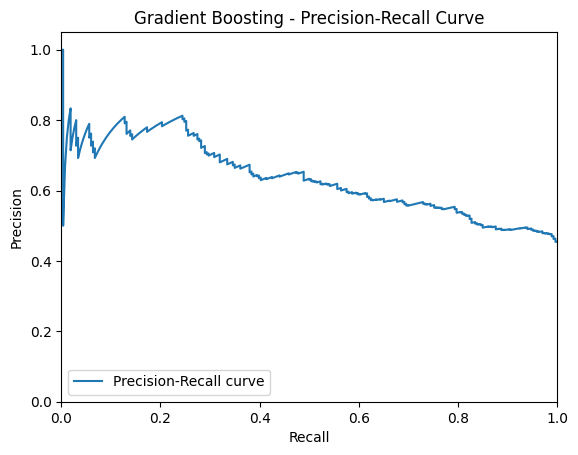

 69%|██████▉   | 9/13 [00:20<00:08,  2.15s/it]


Confusion Matrix:
 [[193 126]
 [107 159]]


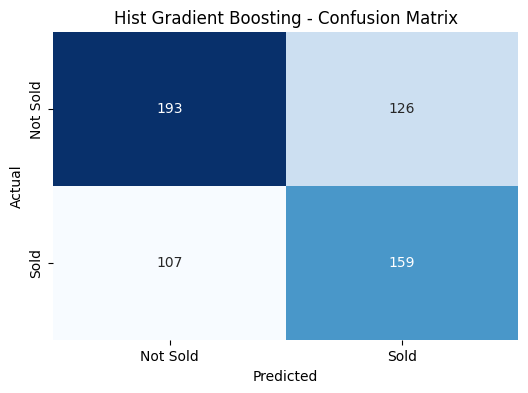


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.64      0.61      0.62       319
    Sold within 30 days       0.56      0.60      0.58       266

               accuracy                           0.60       585
              macro avg       0.60      0.60      0.60       585
           weighted avg       0.60      0.60      0.60       585

ROC-AUC: 0.6525090154854221


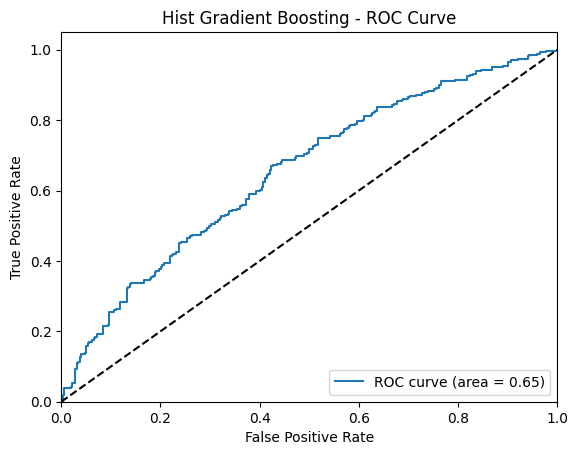

PR AUC: 0.5972261212762345


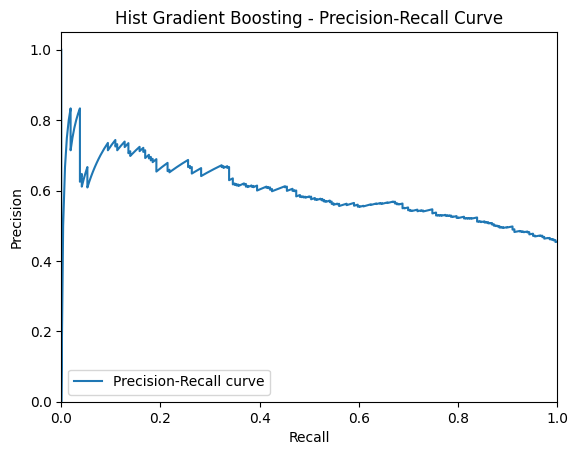

 77%|███████▋  | 10/13 [00:22<00:06,  2.04s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:58:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[203 116]
 [105 161]]


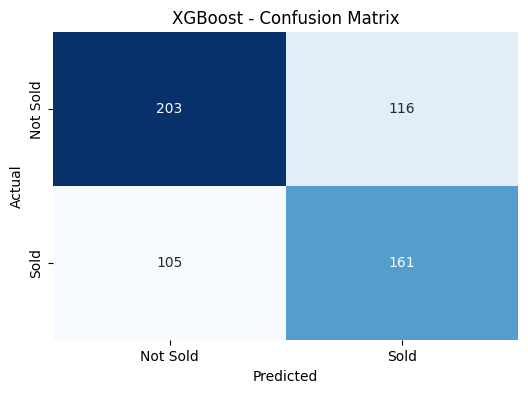


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.66      0.64      0.65       319
    Sold within 30 days       0.58      0.61      0.59       266

               accuracy                           0.62       585
              macro avg       0.62      0.62      0.62       585
           weighted avg       0.62      0.62      0.62       585

ROC-AUC: 0.6563037688264547


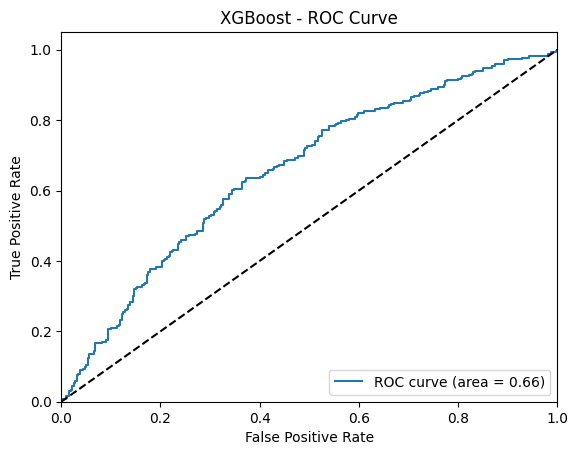

PR AUC: 0.583546378345754


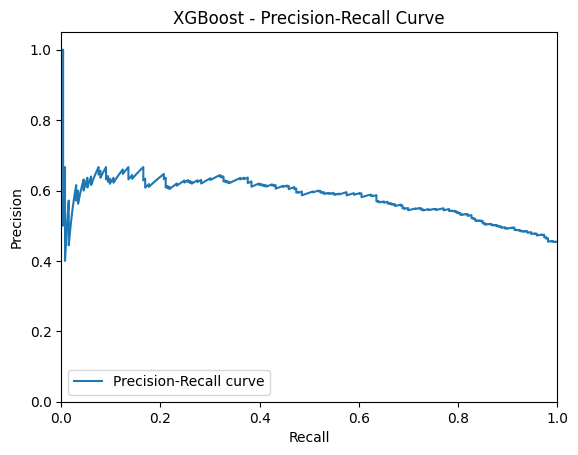

 85%|████████▍ | 11/13 [00:27<00:05,  2.76s/it]


Confusion Matrix:
 [[216 103]
 [109 157]]


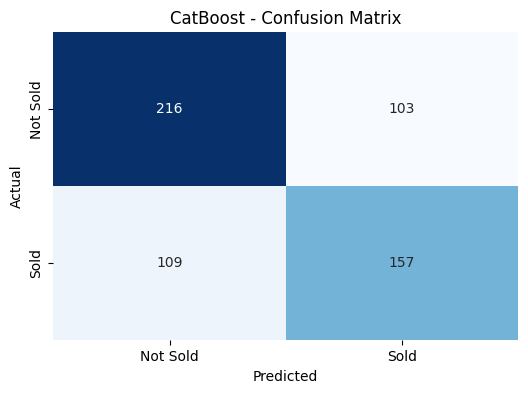


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.66      0.68      0.67       319
    Sold within 30 days       0.60      0.59      0.60       266

               accuracy                           0.64       585
              macro avg       0.63      0.63      0.63       585
           weighted avg       0.64      0.64      0.64       585

ROC-AUC: 0.6870742687439602


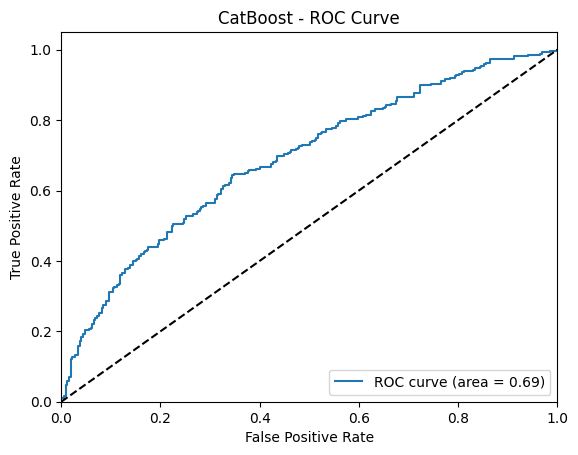

PR AUC: 0.6455676684303269


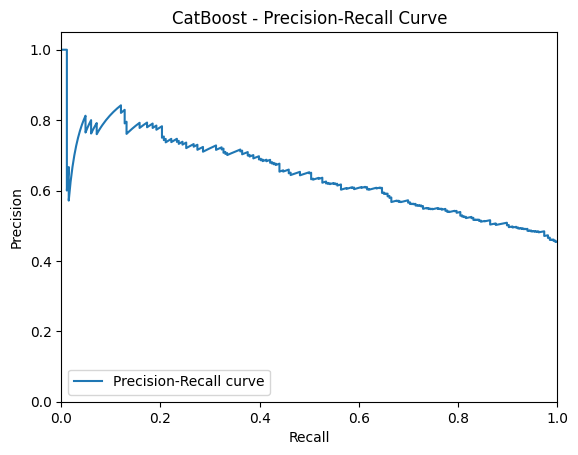

 92%|█████████▏| 12/13 [00:32<00:03,  3.69s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 1061, number of negative: 1275
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002706 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 742
[LightGBM] [Info] Number of data points in the train set: 2336, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.454195 -> initscore=-0.183734
[LightGBM] [Info] Start training from score -0.183734

Confusion Matrix:
 [[200 119]
 [109 157]]


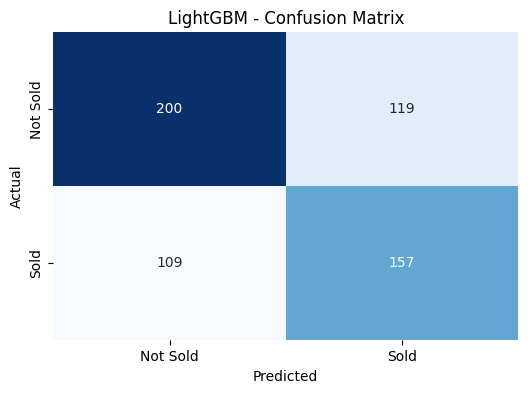

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.65      0.63      0.64       319
    Sold within 30 days       0.57      0.59      0.58       266

               accuracy                           0.61       585
              macro avg       0.61      0.61      0.61       585
           weighted avg       0.61      0.61      0.61       585

ROC-AUC: 0.6650128455936078


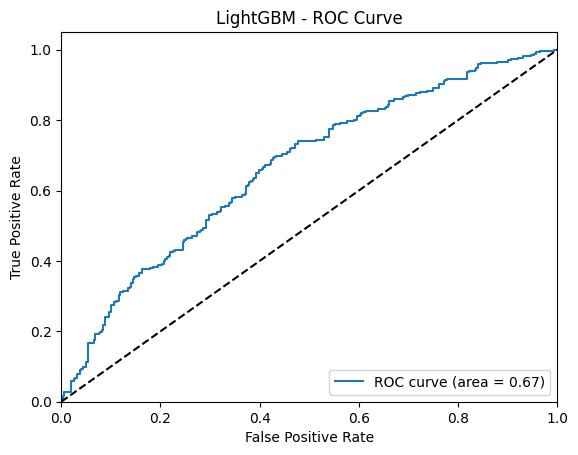

PR AUC: 0.6024345070964063


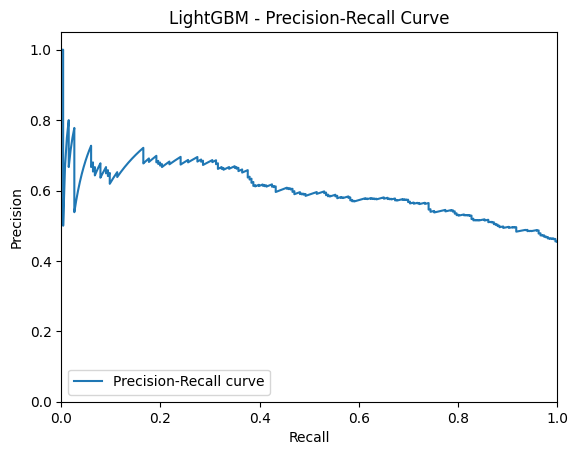

100%|██████████| 13/13 [00:33<00:00,  2.58s/it]


In [51]:

results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
                xticklabels=['Not Sold', 'Sold'],
                yticklabels=['Not Sold', 'Sold'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'{name} - Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=['Not Sold within 30 days', 'Sold within 30 days'],
        zero_division=0
    ))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{name} - ROC Curve')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(
        y_test, y_pred_prob
    )

    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'{name} - Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, zero_division=0),
        "Test Precision": precision_score(y_test, test_pred, zero_division=0),
        "Train Recall": recall_score(y_train, train_pred, zero_division=0),
        "Test Recall": recall_score(y_test, test_pred, zero_division=0),
        "Train F1 Score": f1_score(y_train, train_pred, zero_division=0),
        "Test F1 Score": f1_score(y_test, test_pred, zero_division=0),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:58:20] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[196 123]
 [100 166]]


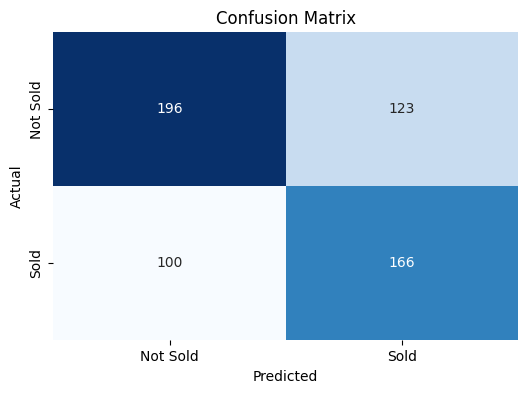


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.66      0.61      0.64       319
    Sold within 30 days       0.57      0.62      0.60       266

               accuracy                           0.62       585
              macro avg       0.62      0.62      0.62       585
           weighted avg       0.62      0.62      0.62       585

ROC-AUC: 0.6610059631838217


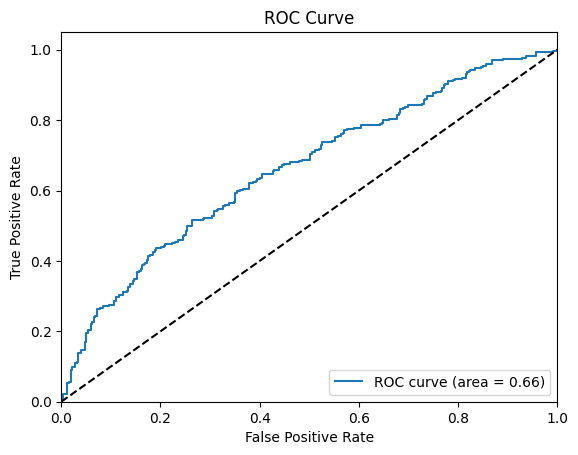

PR AUC: 0.6202811896820519


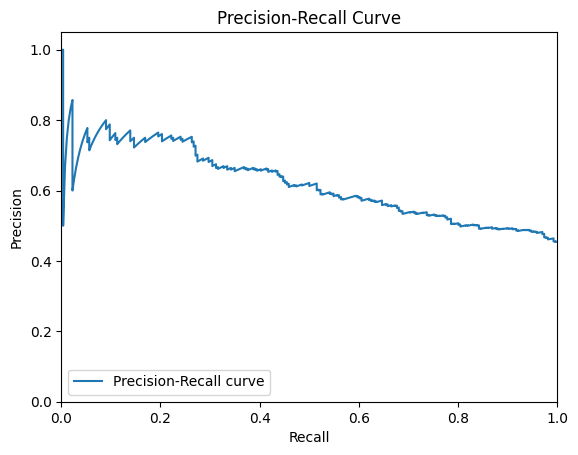

In [52]:

voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)

voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)

cm = confusion_matrix(y_test, voting_test_pred, labels=[0, 1])
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
            xticklabels=['Not Sold', 'Sold'],
            yticklabels=['Not Sold', 'Sold'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    voting_test_pred,
    labels=[0, 1],
    target_names=['Not Sold within 30 days', 'Sold within 30 days'],
    zero_division=0
))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(
    y_test, y_pred_prob
)

plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, zero_division=0),
    "Test Precision": precision_score(y_test, voting_test_pred, zero_division=0),
    "Train Recall": recall_score(y_train, voting_train_pred, zero_division=0),
    "Test Recall": recall_score(y_test, voting_test_pred, zero_division=0),
    "Train F1 Score": f1_score(y_train, voting_train_pred, zero_division=0),
    "Test F1 Score": f1_score(y_test, voting_test_pred, zero_division=0),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Confusion Matrix:
 [[191 128]
 [119 147]]


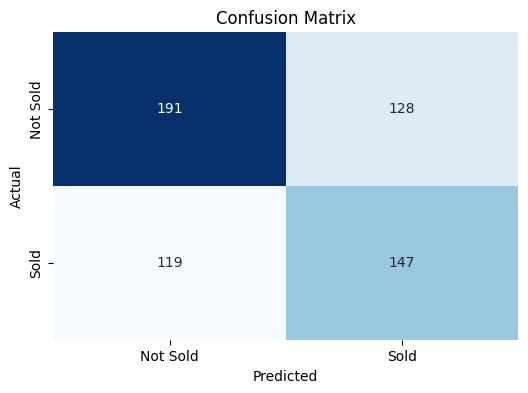


Classification Report:

                         precision    recall  f1-score   support

Not Sold within 30 days       0.62      0.60      0.61       319
    Sold within 30 days       0.53      0.55      0.54       266

               accuracy                           0.58       585
              macro avg       0.58      0.58      0.58       585
           weighted avg       0.58      0.58      0.58       585

ROC-AUC: 0.6228404082306078


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


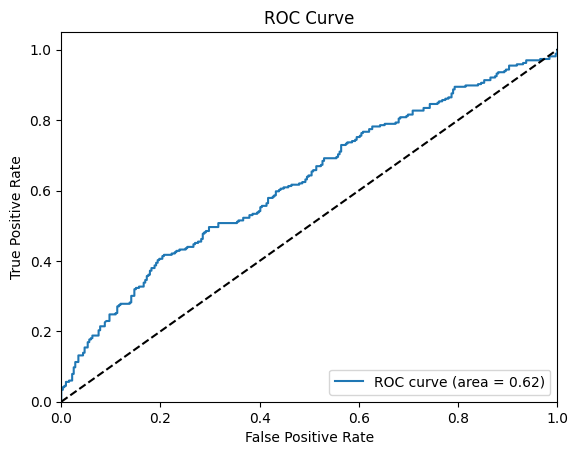

PR AUC: 0.5989608955252337


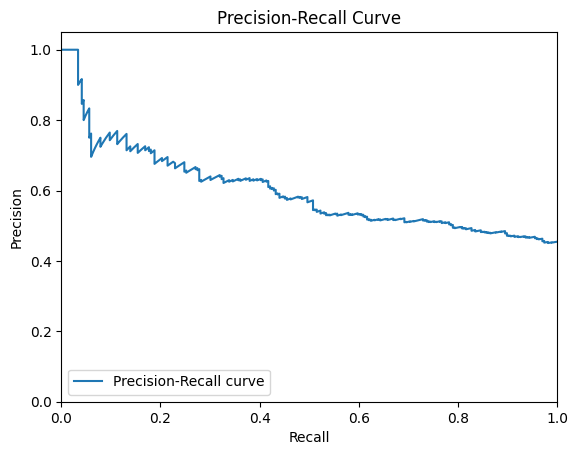

In [53]:

stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(n_estimators=2000),
    stack_method="predict_proba",
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred, labels=[0, 1])
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
            xticklabels=['Not Sold', 'Sold'],
            yticklabels=['Not Sold', 'Sold'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    stack_auto_test_pred,
    labels=[0, 1],
    target_names=['Not Sold within 30 days', 'Sold within 30 days'],
    zero_division=0
))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(
    y_test, y_pred_prob
)

plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


In [60]:
results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(
    by="Test F1 Score",
    ascending=False
)

results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Logistic Regression,0.674658,0.664957,0.658254,0.644628,0.590009,0.586466,0.622266,0.614173,0.667554,0.658437,0.711776,0.673968
AdaBoost,0.656678,0.670085,0.651109,0.658009,0.525919,0.571429,0.581856,0.611670,0.645705,0.661890,0.700156,0.671831
Voting Classifier,0.893836,0.618803,0.889741,0.574394,0.874647,0.624060,0.882129,0.598198,0.892225,0.619240,0.661006,0.620281
CatBoost,0.886986,0.637607,0.909558,0.603846,0.834119,0.590226,0.870206,0.596958,0.882550,0.633671,0.687074,0.645568
Random Forest,1.000000,0.644444,1.000000,0.616000,1.000000,0.578947,1.000000,0.596899,1.000000,0.639003,0.675902,0.617918
XGBoost,0.994007,0.622222,0.996209,0.581227,0.990575,0.605263,0.993384,0.593002,0.993719,0.620813,0.656304,0.583546
Gradient Boosting,0.749144,0.634188,0.751856,0.606557,0.668238,0.556391,0.707585,0.580392,0.742354,0.627725,0.679673,0.636199
LightGBM,0.922945,0.610256,0.933990,0.568841,0.893497,0.590226,0.913295,0.579336,0.920474,0.608592,0.665013,0.602435
SVC,0.786815,0.622222,0.803014,0.587549,0.703110,0.567669,0.749749,0.577438,0.779790,0.617690,0.667664,0.640813
Hist Gradient Boosting,0.924229,0.601709,0.926641,0.557895,0.904807,0.597744,0.915594,0.577132,0.922599,0.601380,0.652509,0.597226


In [61]:
model_comparison = results_df[
    [
        "Train F1 Score",
        "Test F1 Score",
        "Test Precision",
        "Test Recall",
        "Test Balanced Accuracy",
        "ROC-AUC",
        "PR AUC"
    ]
].copy()

model_comparison["F1 Gap"] = (
    model_comparison["Train F1 Score"] -
    model_comparison["Test F1 Score"]
)

model_comparison.sort_values(
    by="Test F1 Score",
    ascending=False
)

,Train F1 Score,Test F1 Score,Test Precision,Test Recall,Test Balanced Accuracy,ROC-AUC,PR AUC,F1 Gap
Logistic Regression,0.622266,0.614173,0.644628,0.586466,0.658437,0.711776,0.673968,0.008093
AdaBoost,0.581856,0.611670,0.658009,0.571429,0.661890,0.700156,0.671831,-0.029814
Voting Classifier,0.882129,0.598198,0.574394,0.624060,0.619240,0.661006,0.620281,0.283931
CatBoost,0.870206,0.596958,0.603846,0.590226,0.633671,0.687074,0.645568,0.273248
Random Forest,1.000000,0.596899,0.616000,0.578947,0.639003,0.675902,0.617918,0.403101
XGBoost,0.993384,0.593002,0.581227,0.605263,0.620813,0.656304,0.583546,0.400382
Gradient Boosting,0.707585,0.580392,0.606557,0.556391,0.627725,0.679673,0.636199,0.127193
LightGBM,0.913295,0.579336,0.568841,0.590226,0.608592,0.665013,0.602435,0.333959
SVC,0.749749,0.577438,0.587549,0.567669,0.617690,0.667664,0.640813,0.172311
Hist Gradient Boosting,0.915594,0.577132,0.557895,0.597744,0.601380,0.652509,0.597226,0.338461


In [64]:
import joblib

best_model_name = results_df["Test F1 Score"].idxmax()
best_model = models[best_model_name]

joblib.dump(best_model, "best_used_car_model.pkl")

print("Best Model:", best_model_name)
print("Best model saved successfully!")

Best Model: Logistic Regression
Best model saved successfully!


In [65]:
artifacts = {
    "model": best_model,
    "model_name": best_model_name,
    "num_imputer": num_imputer,
    "cat_imputer": cat_imputer,
    "scaler": scaler,
    "input_columns": X.columns.tolist(),
    "feature_columns": feature_columns,
    "numeric_cols": num_cols,
    "categorical_cols": cat_cols
}

joblib.dump(artifacts, "used_car_sale_artifacts.pkl")

print("Model and preprocessing saved successfully!")

Model and preprocessing saved successfully!


In [66]:
artifacts = joblib.load("used_car_sale_artifacts.pkl")

best_model = artifacts["model"]
best_model_name = artifacts["model_name"]

num_imputer = artifacts["num_imputer"]
cat_imputer = artifacts["cat_imputer"]
scaler = artifacts["scaler"]

input_columns = artifacts["input_columns"]
feature_columns = artifacts["feature_columns"]

numeric_cols = artifacts["numeric_cols"]
categorical_cols = artifacts["categorical_cols"]

In [69]:

import gradio as gr

def predict(
    brand, model, year, mileage_km, transmission, fuel_type,
    engine_cc, body_type, color, city, seller_type,
    accident_history, previous_owners, condition_rating,
    photos_count, price_egp
):

    input_data = pd.DataFrame([{
        "brand": brand,
        "model": model,
        "year": year,
        "mileage_km": mileage_km,
        "transmission": transmission,
        "fuel_type": fuel_type,
        "engine_cc": engine_cc,
        "body_type": body_type,
        "color": color,
        "city": city,
        "seller_type": seller_type,
        "accident_history": accident_history,
        "previous_owners": previous_owners,
        "condition_rating": condition_rating,
        "photos_count": photos_count,
        "price_egp": price_egp
    }])

    input_data = input_data[input_columns]

    X_num = input_data[numeric_cols].copy()
    X_cat = input_data[categorical_cols].copy()

    X_num = pd.DataFrame(
        num_imputer.transform(X_num),
        columns=numeric_cols
    )

    X_cat = pd.DataFrame(
        cat_imputer.transform(X_cat),
        columns=categorical_cols
    )

    X_input = pd.concat([X_num, X_cat], axis=1)
    X_input = X_input[input_columns]

    X_input = pd.get_dummies(
        X_input,
        columns=categorical_cols,
        dtype=int
    )

    X_input = X_input.reindex(
        columns=feature_columns,
        fill_value=0
    )

    if best_model_name in ["Logistic Regression", "KNN", "SVM"]:
        X_input = scaler.transform(X_input)

    prediction = best_model.predict(X_input)[0]

    if prediction == 1:
        return "The car is predicted to be SOLD within 30 days."
    else:
        return "The car is predicted NOT to be sold within 30 days."


demo = gr.Interface(
    fn=predict,

    inputs=[
        gr.Dropdown(
            choices=sorted(df["brand"].dropna().unique().tolist()),
            label="Brand"
        ),

        gr.Dropdown(
            choices=sorted(df["model"].dropna().unique().tolist()),
            label="Model"
        ),

        gr.Number(label="Year", precision=0),
        gr.Number(label="Mileage (KM)", precision=0),

        gr.Dropdown(
            ["Automatic", "Manual"],
            label="Transmission"
        ),

        gr.Dropdown(
            ["Petrol", "Diesel", "Electric", "Hybrid"],
            label="Fuel Type"
        ),

        gr.Number(label="Engine CC", precision=0),

        gr.Dropdown(
            choices=sorted(df["body_type"].dropna().unique().tolist()),
            label="Body Type"
        ),

        gr.Dropdown(
            choices=sorted(df["color"].dropna().unique().tolist()),
            label="Color"
        ),

        gr.Dropdown(
            choices=sorted(df["city"].dropna().unique().tolist()),
            label="City"
        ),

        gr.Dropdown(
            ["Dealer", "Individual"],
            label="Seller Type"
        ),

        gr.Dropdown(
            ["Yes", "No"],
            label="Accident History"
        ),

        gr.Number(label="Previous Owners", precision=0),
        gr.Number(label="Condition Rating", precision=0),
        gr.Number(label="Photos Count", precision=0),
        gr.Number(label="Price (EGP)")
    ],

    outputs=gr.Textbox(label="Prediction"),

    title="Used Car Sale Prediction",

    description="Predict whether a used car will be sold within 30 days."
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2c3bbfe7212b7a120a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
